# preliminary svm model

In [1]:

from pathlib import Path

import numpy as np
import pandas as pd

base_dir = Path("/Volumes/WD_BLACK/Spikes2Slope")
results_dir = base_dir / "opto_results"

master = pd.read_csv(
    results_dir / "master_waveform_features.csv"
)

waveform_features = [
    "waveform_duration",
    "waveform_halfwidth",
    "waveform_PT_ratio",
    "waveform_repolarization_slope",
    "waveform_recovery_slope",
    "waveform_amplitude",
    "waveform_spread",
]

model_data = master.loc[
    master["cell_type_label"].isin(["Pvalb", "Sst", "Vip"])
].copy()

X = model_data[waveform_features]
y = model_data["cell_type_label"]
groups = model_data["ecephys_session_id"]

print("Samples:", len(X))
print("Features:", X.shape[1])
print("Sessions:", groups.nunique())

print("\nClass distribution:")
print(y.value_counts())

print("\nMissing feature values:")
print(X.isna().sum())


Samples: 1127
Features: 7
Sessions: 28

Class distribution:
Sst      535
Pvalb    345
Vip      247
Name: cell_type_label, dtype: int64

Missing feature values:
waveform_duration                 0
waveform_halfwidth               16
waveform_PT_ratio                 0
waveform_repolarization_slope     0
waveform_recovery_slope          16
waveform_amplitude                0
waveform_spread                   0
dtype: int64


### 5 fold StratifiedGroupKFold cv

In [2]:

from sklearn.model_selection import StratifiedKFold

session_labels = (
    model_data.groupby("ecephys_session_id")["cell_type_label"]
    .first()
)

assert (
    model_data.groupby("ecephys_session_id")["cell_type_label"]
    .nunique() == 1
).all()

session_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = []
summary = []

for fold, (train_s, test_s) in enumerate(
    session_cv.split(
        session_labels.index,
        session_labels.values
    ),
    start=1
):
    train_sessions = session_labels.index[train_s]
    test_sessions = session_labels.index[test_s]

    train_idx = np.flatnonzero(groups.isin(train_sessions))
    test_idx = np.flatnonzero(groups.isin(test_sessions))

    assert set(groups.iloc[train_idx]).isdisjoint(
        set(groups.iloc[test_idx])
    )

    folds.append((train_idx, test_idx))

    train_counts = y.iloc[train_idx].value_counts()
    test_counts = y.iloc[test_idx].value_counts()

    summary.append({
        "fold": fold,
        "train_sessions": len(train_sessions),
        "test_sessions": len(test_sessions),
        "train_Pvalb": train_counts.get("Pvalb", 0),
        "train_Sst": train_counts.get("Sst", 0),
        "train_Vip": train_counts.get("Vip", 0),
        "test_Pvalb": test_counts.get("Pvalb", 0),
        "test_Sst": test_counts.get("Sst", 0),
        "test_Vip": test_counts.get("Vip", 0),
    })

fold_summary = pd.DataFrame(summary)
display(fold_summary)

assert (
    fold_summary[
        ["train_Pvalb", "train_Sst", "train_Vip",
         "test_Pvalb", "test_Sst", "test_Vip"]
    ] > 0
).all().all()

assert sum(len(test_idx) for _, test_idx in folds) == len(X)

print("All folds contain all three classes.")
print("No sessions overlap between training and testing.")


,fold,train_sessions,test_sessions,train_Pvalb,train_Sst,train_Vip,test_Pvalb,test_Sst,test_Vip
0,1,22,6,323,363,197,22,172,50
1,2,22,6,311,407,169,34,128,78
2,3,22,6,232,467,198,113,68,49
3,4,23,5,251,462,226,94,73,21
4,5,23,5,263,441,198,82,94,49


All folds contain all three classes.
No sessions overlap between training and testing.


### train linear svm

In [3]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import balanced_accuracy_score, f1_score

pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=10000
    )
)

results = []

for fold, (train_idx, test_idx) in enumerate(folds, start=1):
    pipeline.fit(X.iloc[train_idx], y.iloc[train_idx])

    predictions = pipeline.predict(X.iloc[test_idx])

    results.append({
        "fold": fold,
        "balanced_accuracy": balanced_accuracy_score(
            y.iloc[test_idx], predictions
        ),
        "macro_f1": f1_score(
            y.iloc[test_idx],
            predictions,
            average="macro"
        )
    })

cv_results = pd.DataFrame(results)

display(cv_results.round(3))

print(
    "Mean balanced accuracy:",
    round(cv_results["balanced_accuracy"].mean(), 3)
)

print(
    "Mean macro-F1:",
    round(cv_results["macro_f1"].mean(), 3)
)


,fold,balanced_accuracy,macro_f1
0,1,0.433,0.358
1,2,0.312,0.306
2,3,0.386,0.347
3,4,0.454,0.450
4,5,0.413,0.405


Mean balanced accuracy: 0.4
Mean macro-F1: 0.373


### confusion matrix

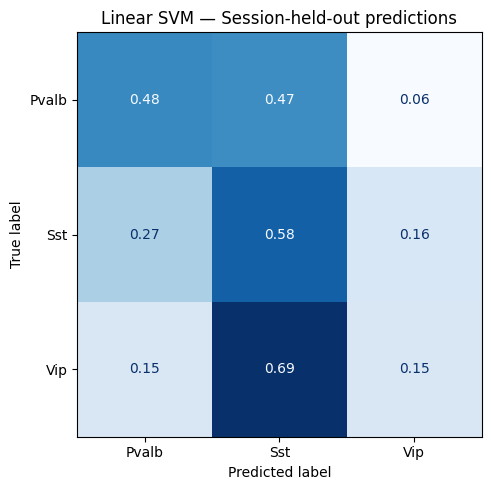

In [4]:

from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

labels = ["Pvalb", "Sst", "Vip"]

oof_predictions = pd.Series(
    index=y.index,
    dtype="object"
)

for train_idx, test_idx in folds:
    model = clone(pipeline)
    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    oof_predictions.iloc[test_idx] = model.predict(
        X.iloc[test_idx]
    )

assert oof_predictions.notna().all()

cm = confusion_matrix(
    y,
    oof_predictions,
    labels=labels,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    colorbar=False
)

ax.set_title("Linear SVM — Session-held-out predictions")
plt.tight_layout()
plt.show()


### nonlinear svm

In [5]:

from sklearn.svm import SVC
from sklearn.base import clone

rbf_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    )
)

rbf_results = []

for fold, (train_idx, test_idx) in enumerate(folds, start=1):
    model = clone(rbf_pipeline)
    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    predictions = model.predict(X.iloc[test_idx])

    rbf_results.append({
        "fold": fold,
        "balanced_accuracy": balanced_accuracy_score(
            y.iloc[test_idx], predictions
        ),
        "macro_f1": f1_score(
            y.iloc[test_idx],
            predictions,
            average="macro"
        )
    })

rbf_results = pd.DataFrame(rbf_results)

comparison = cv_results.merge(
    rbf_results,
    on="fold",
    suffixes=("_linear", "_rbf")
)

display(comparison.round(3))

print(
    "\nMean RBF balanced accuracy:",
    round(rbf_results["balanced_accuracy"].mean(), 3)
)

print(
    "Mean RBF macro-F1:",
    round(rbf_results["macro_f1"].mean(), 3)
)


,fold,balanced_accuracy_linear,macro_f1_linear,balanced_accuracy_rbf,macro_f1_rbf
0,1,0.433,0.358,0.507,0.399
1,2,0.312,0.306,0.341,0.329
2,3,0.386,0.347,0.440,0.426
3,4,0.454,0.450,0.465,0.450
4,5,0.413,0.405,0.467,0.450



Mean RBF balanced accuracy: 0.444
Mean RBF macro-F1: 0.411


### confusion matrix

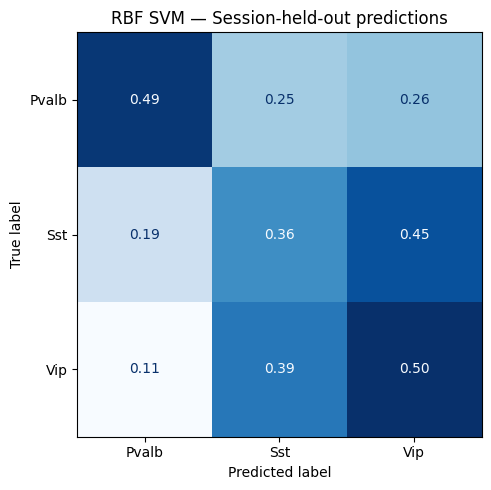

In [6]:

rbf_oof = pd.Series(index=y.index, dtype="object")

for train_idx, test_idx in folds:
    model = clone(rbf_pipeline)
    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    rbf_oof.iloc[test_idx] = model.predict(
        X.iloc[test_idx]
    )

assert rbf_oof.notna().all()

rbf_cm = confusion_matrix(
    y,
    rbf_oof,
    labels=labels,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=rbf_cm,
    display_labels=labels
).plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    colorbar=False
)

ax.set_title("RBF SVM — Session-held-out predictions")
plt.tight_layout()
plt.show()


### try add fire rate

In [7]:

# Add firing rate to the existing waveform features.
extended_features = waveform_features + ["firing_rate"]

X_extended = model_data[extended_features]

extended_results = []

for fold, (train_idx, test_idx) in enumerate(folds, start=1):
    model = clone(rbf_pipeline)

    model.fit(
        X_extended.iloc[train_idx],
        y.iloc[train_idx]
    )

    predictions = model.predict(
        X_extended.iloc[test_idx]
    )

    extended_results.append({
        "fold": fold,
        "balanced_accuracy": balanced_accuracy_score(
            y.iloc[test_idx],
            predictions
        ),
        "macro_f1": f1_score(
            y.iloc[test_idx],
            predictions,
            average="macro"
        )
    })

extended_results = pd.DataFrame(extended_results)

feature_comparison = rbf_results.merge(
    extended_results,
    on="fold",
    suffixes=("_waveform", "_with_firing_rate")
)

display(feature_comparison.round(3))

print(
    "\nWaveform-only balanced accuracy:",
    round(rbf_results["balanced_accuracy"].mean(), 3)
)

print(
    "With firing rate balanced accuracy:",
    round(extended_results["balanced_accuracy"].mean(), 3)
)

print(
    "\nWaveform-only macro-F1:",
    round(rbf_results["macro_f1"].mean(), 3)
)

print(
    "With firing rate macro-F1:",
    round(extended_results["macro_f1"].mean(), 3)
)


,fold,balanced_accuracy_waveform,macro_f1_waveform,balanced_accuracy_with_firing_rate,macro_f1_with_firing_rate
0,1,0.507,0.399,0.543,0.445
1,2,0.341,0.329,0.363,0.360
2,3,0.440,0.426,0.402,0.388
3,4,0.465,0.450,0.508,0.477
4,5,0.467,0.450,0.443,0.439



Waveform-only balanced accuracy: 0.444
With firing rate balanced accuracy: 0.452

Waveform-only macro-F1: 0.411
With firing rate macro-F1: 0.422


## Preliminary Findings

We trained linear and RBF support vector machines to classify optotagging-supported Pvalb, Sst, and Vip candidates using Allen-computed extracellular waveform features.

The dataset contained 1,127 candidate units from 28 recording sessions. Models were evaluated using five session-disjoint cross-validation folds to reduce recording-specific leakage.

**Results:**
- Linear SVM (waveform only): 40.0% balanced accuracy
- RBF SVM (waveform only): 44.4% balanced accuracy
- RBF SVM (waveform + firing rate): 45.2% balanced accuracy

The RBF SVM modestly outperformed the linear model, suggesting that nonlinear relationships among waveform features may contribute to classification. Adding firing rate produced only a small additional improvement.

Confusion matrices revealed substantial overlap between SST and VIP candidates, limiting subclass-specific prediction.

**Conclusion:** Conventional extracellular waveform features provide modest discrimination among optotagging-supported interneuron populations. Additional electrophysiological information, potentially including spike-train temporal statistics or PhysMAP-derived representations, may be necessary to improve classification.

**Limitations:** Candidate labels are based on an Allen-tutorial-derived optotagging criterion rather than definitive molecular identification. Session-disjoint validation reduces leakage but cannot eliminate genotype-associated confounding. These results are exploratory and have not been evaluated against a permutation-based null distribution.